In [1]:
%%HTML

<link rel="stylesheet" href="../custom.css"/> 

### Pseudosections
* Horizontal location as the midpoint of the ABMN array (logical)
* Depth???
  * Larger electrode spacing ~ sensitive to deeper structures.
  * The depth axis is usually array length / 2. It's a pseudo-depth: deeper rows come from wider spacings, which are sensitive to deeper ground, but it is **not** a true depth. Don't read a pseudosection like a cross-section.

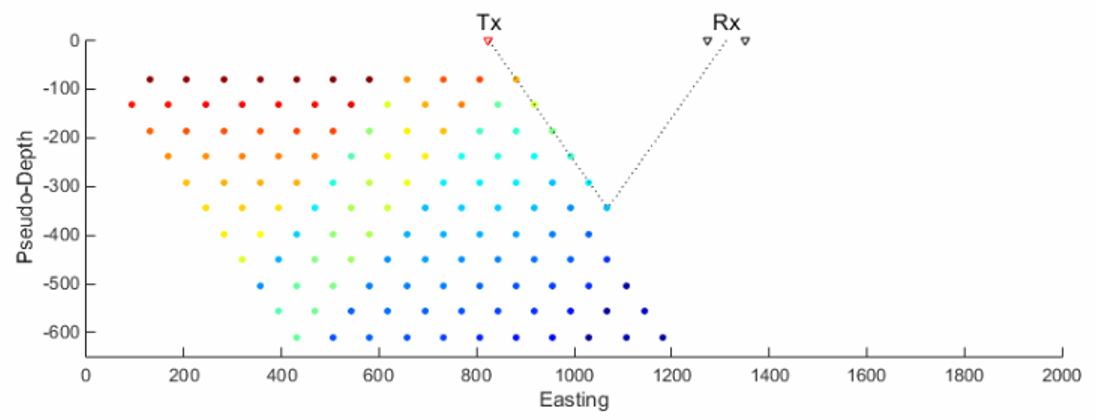

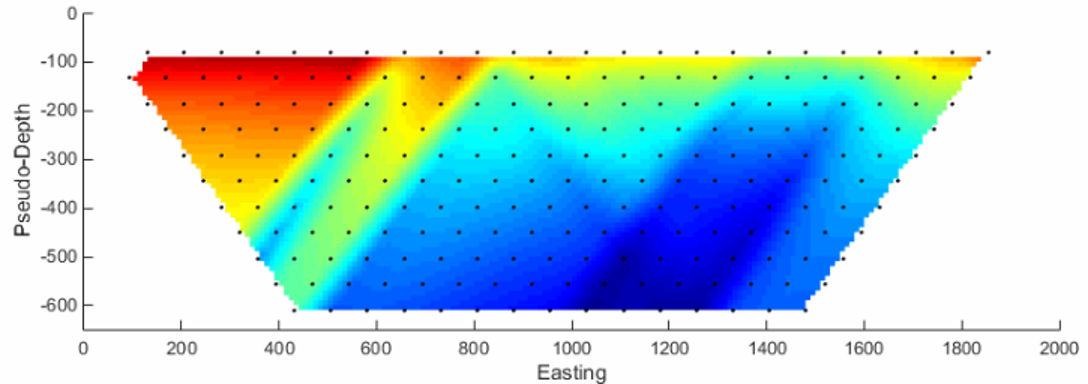

* "Easy" to interpret for simple geometries:

![model](resources/16-simpeg-model.png)

![data](resources/16-simpeg-app-conductivity.png)

* Quickly complicated by different geological structures and array configurations

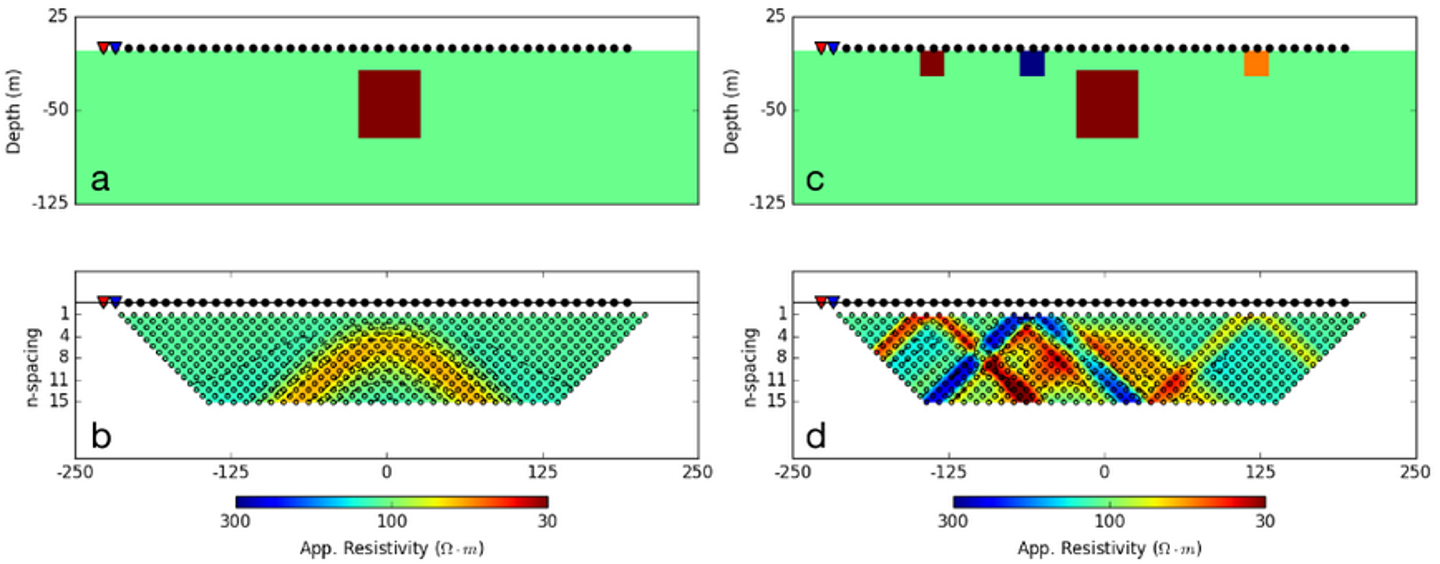

* And topography

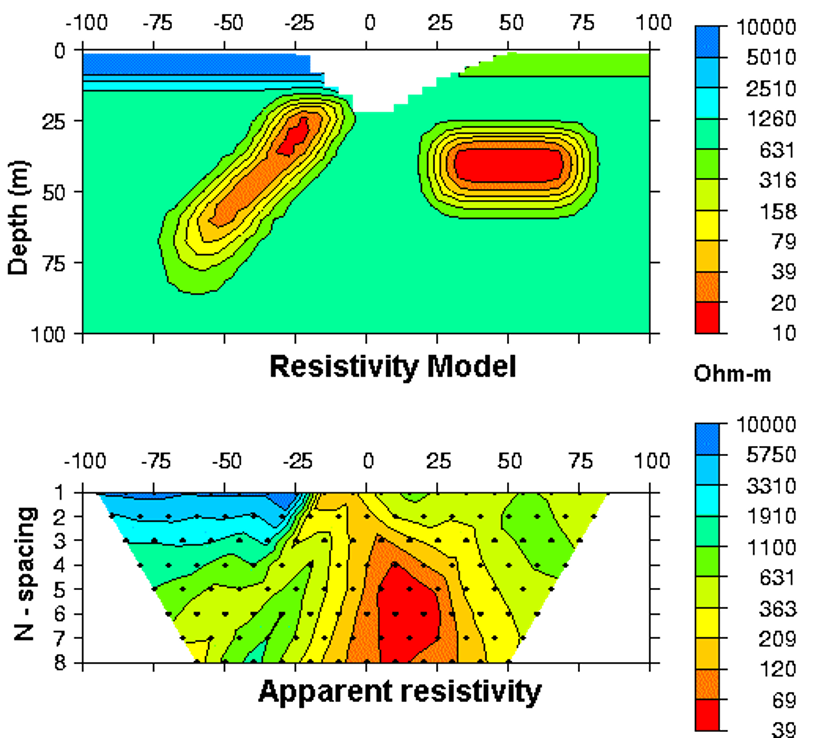

So how do we interpret resistivity data in complex environments?

# Inversion 
How do we interpret all this data?

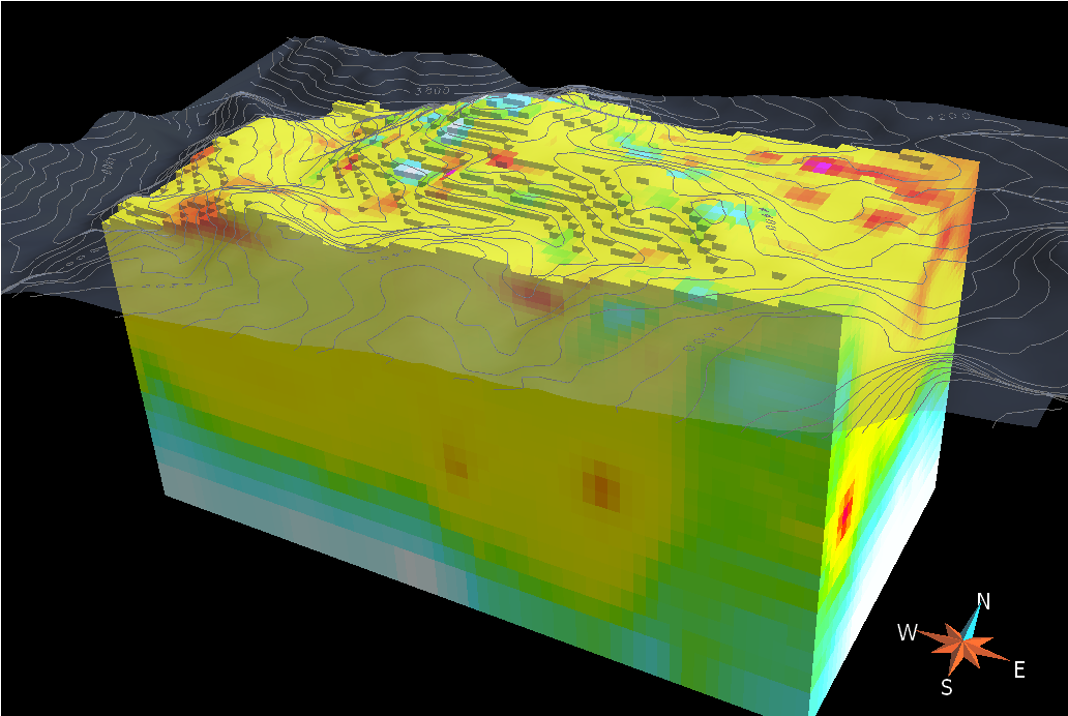

## Geophysical inversion
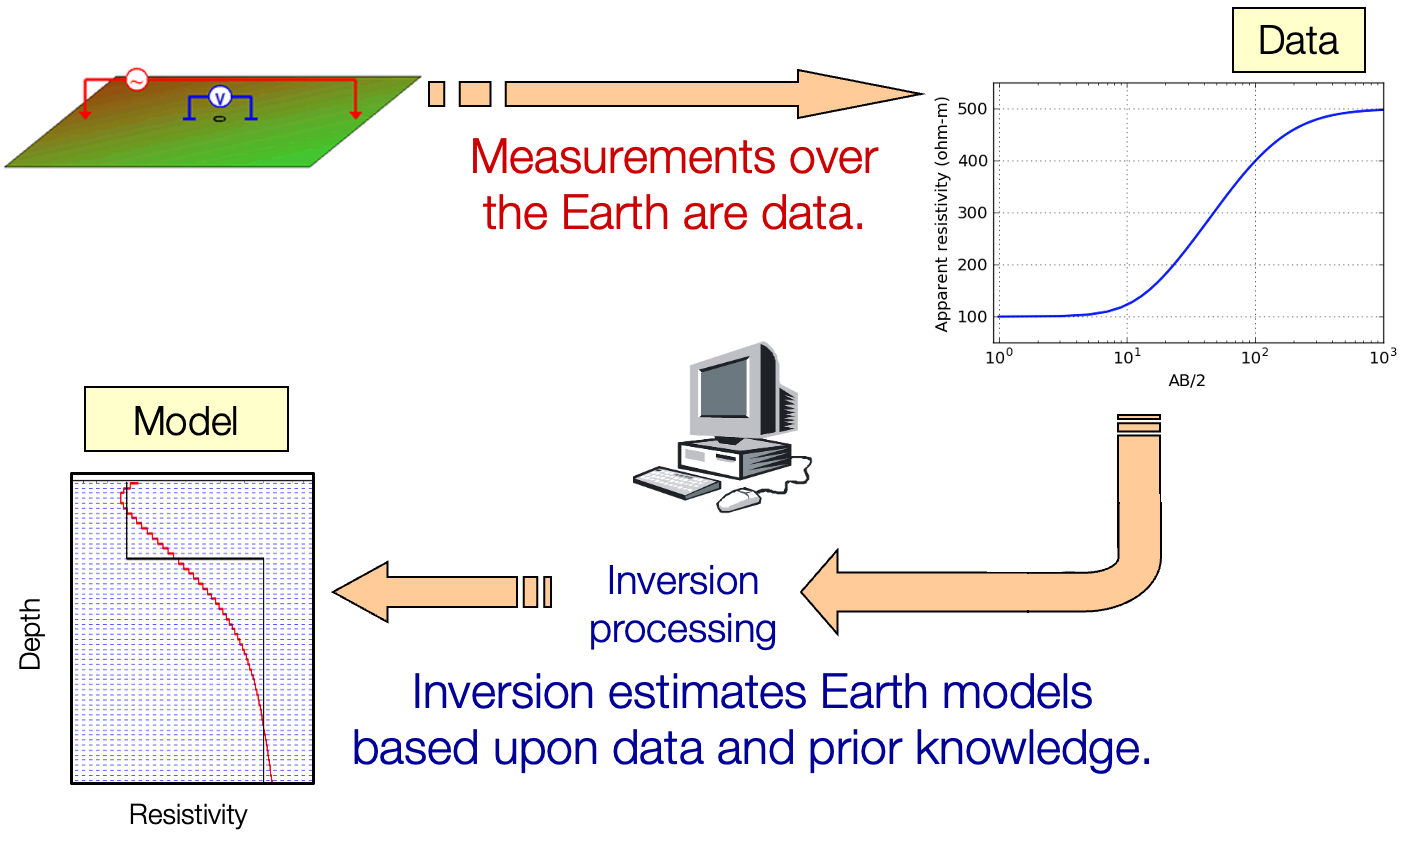

### Goal of inversion:
<div class="row">
<div class="column">

Find a resistivity (conductivity) model that:
* Explains the data
* Represents the true geology

</div>
<div class="column">

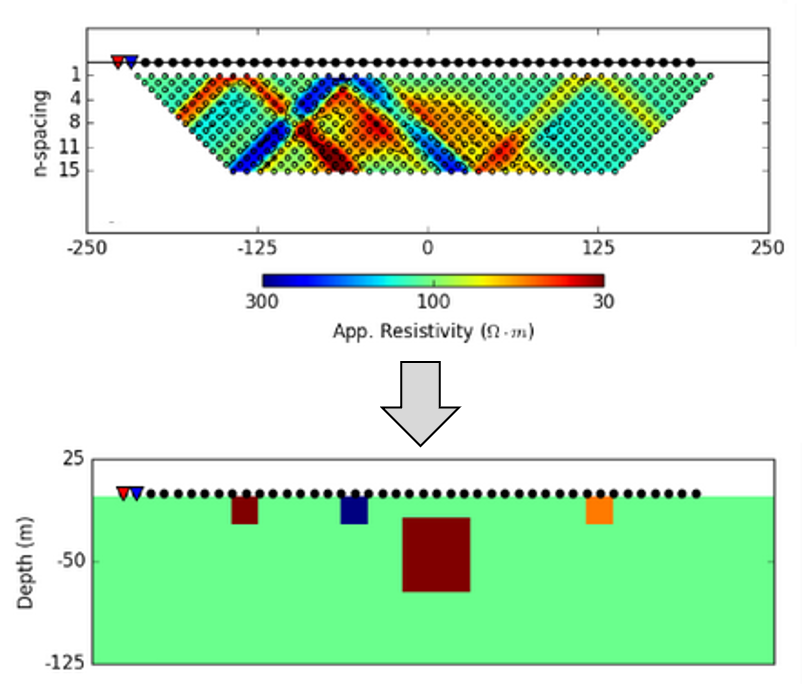
</div>
</div>

### Goal of inversion:
<div class="row">
<div class="column">

* Inversion does **not** recover the true model
* Recovers an approximate, geologically reasonable model
* Solution is **non-unique**
* Recovers structures represented in the data

</div>
<div class="column">

![model](resources/16-simpeg-model.png)

![data](resources/16-simpeg-app-resistivity.png)

![inversion](resources/16-simpeg-recovered-model.png)

*Figures: SimPEG user tutorials (simpeg.xyz), CC BY 4.0*
</div>
</div>

### Pseudo-Section vs Inversion
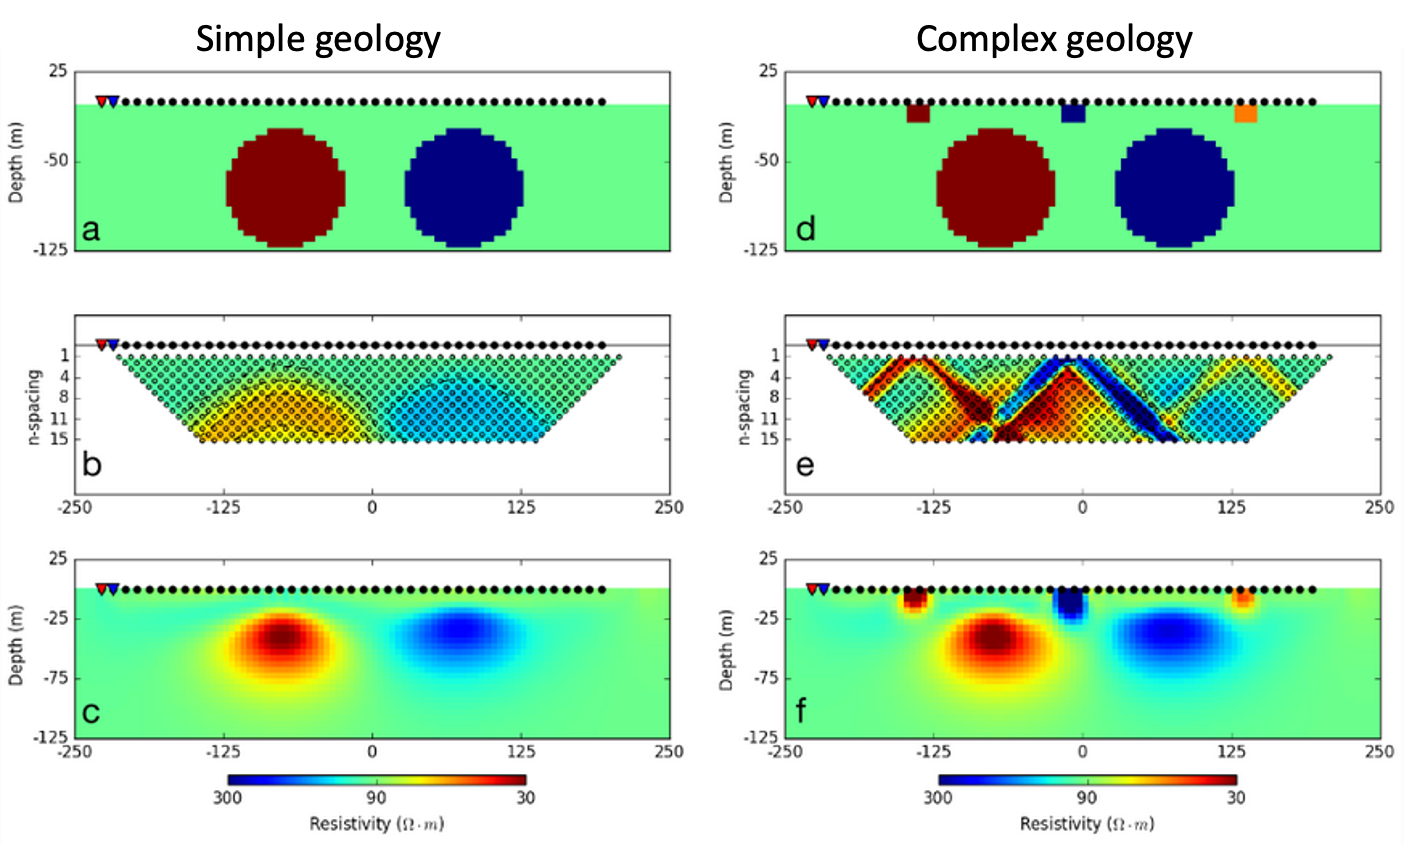

### Inversion Requirements

The basic setup:

$$\mathbf{d} = \mathbf{G}\mathbf{m} + \mathbf{n}$$

* $\mathbf{d}$: **data**, what we measured ($V_M - V_N$, or V/I)
* $\mathbf{m}$: **model**, the resistivity of every cell in the ground (what we want)
* $\mathbf{G}$: **forward operator**, the physics that turns a model into data
* $\mathbf{n}$: **noise**, every measurement has some

(Heads up: this $\mathbf{G}$ is *not* the geometric factor from earlier. Same letter, different job.)

1. **A physical model (respects the physics)**: this is $\mathbf{G}$
$$\nabla \cdot \sigma \nabla V = -I\delta(\vec{r} - \vec{r}_s)$$

2. **Field observations (must fit data)**: this is $\mathbf{d}$
$$d = V_M - V_N$$
Fit them only as well as the noise allows. Fitting the noise exactly creates fake structure.

3. **A starting model**: the initial guess for $\mathbf{m}$ (often a uniform halfspace at the average $\rho_a$)

4. **A reference model**: what we expect $\mathbf{m}$ to look like, $\mathbf{m}_{ref}$

5. **Constraints**: keep $\mathbf{m}$ geologically reasonable (smooth, close to the reference, physically possible values)

### Putting it together: the objective function
The inversion searches for the model that makes this as small as possible:

$$\phi(\mathbf{m}) = \underbrace{\phi_d}_{\text{fit the data}} + \beta \underbrace{\phi_m}_{\text{be reasonable}}$$

* $\phi_d$, **data misfit**: how far the predicted data $\mathbf{G}\mathbf{m}$ are from the observed $\mathbf{d}$, scaled by the noise
* $\phi_m$, **model regularization**: how rough or how far from $\mathbf{m}_{ref}$ the model is
* $\beta$: the trade-off knob between the two

Creates a geologically representative resistivity model.

### Inversion Requirements Cont.

<div class="row">
<div class="column">
    
1) A physical model (respects the physics) $$ \nabla \cdot \sigma \nabla V = -I\delta(\vec{r} - \vec{r}_s) $$
1) Field observations (must fit data) $$ data = V_M - V_N$$
1) A starting model (initial guess)
1) Reference model (impose suspected features)
1) Constraints
   * Geologically reasonable solution

Creates a geologically representative resistivity model
</div>
<div class="column">

Q: If the recovered model
* doesn’t fit the data
* is geologically reasonable  
is it a good solution?

Q: If the recovered model
* fits the data
* isn’t geologically reasonable  
is it a good solution?
</div>
</div>

## Examples:

### Layered Halfspace
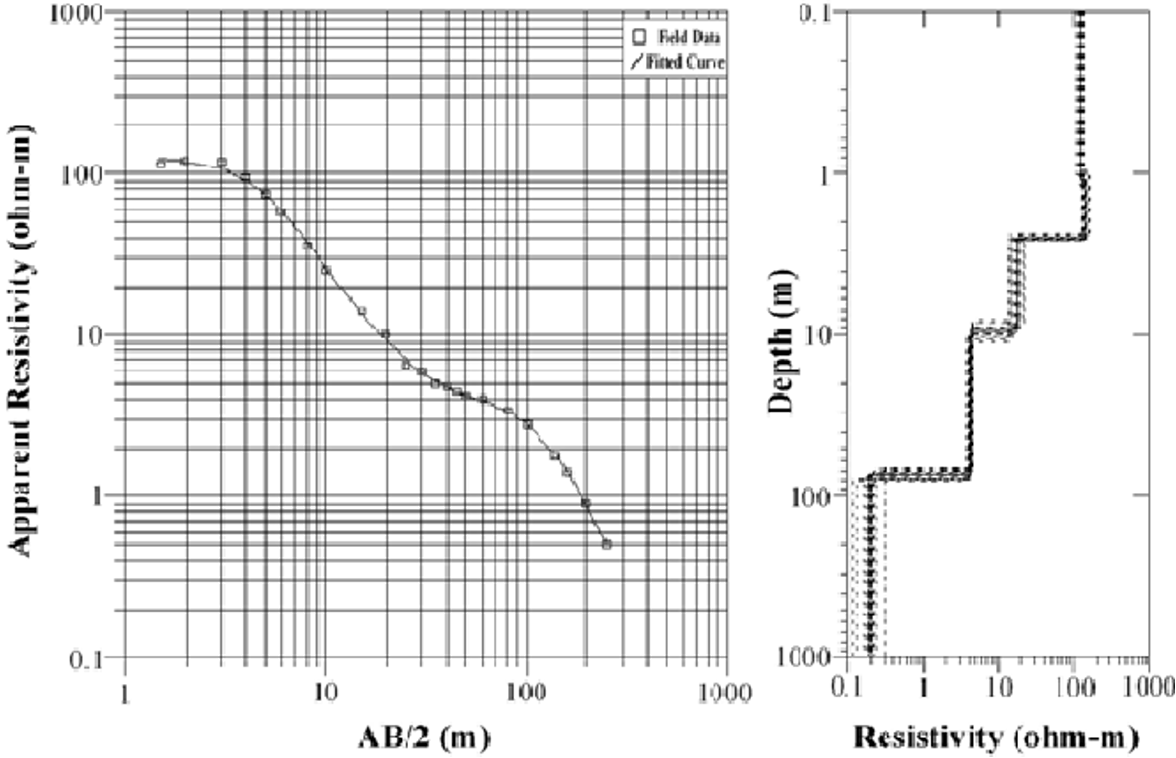

### Buried Prism:
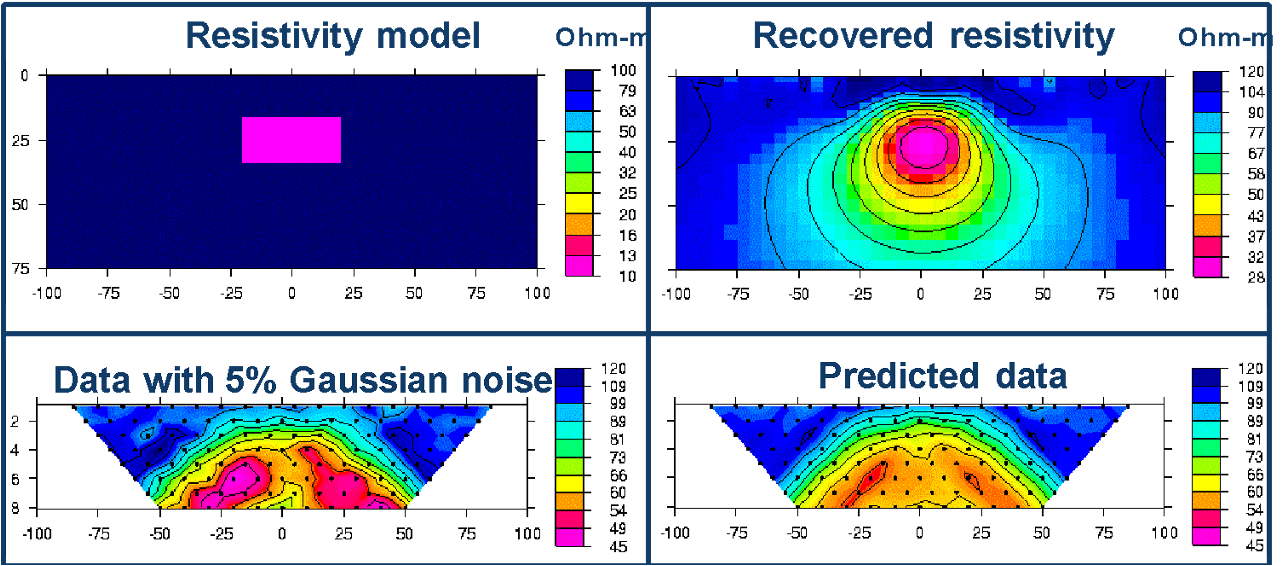
* Dipole-dipole;  n=1,8;  a=10m;  N=316;  ($\alpha_s$, $\alpha_x$, $\alpha_z$)=(.001, 1.0, 1.0)

### Prism with "geologic" noise:
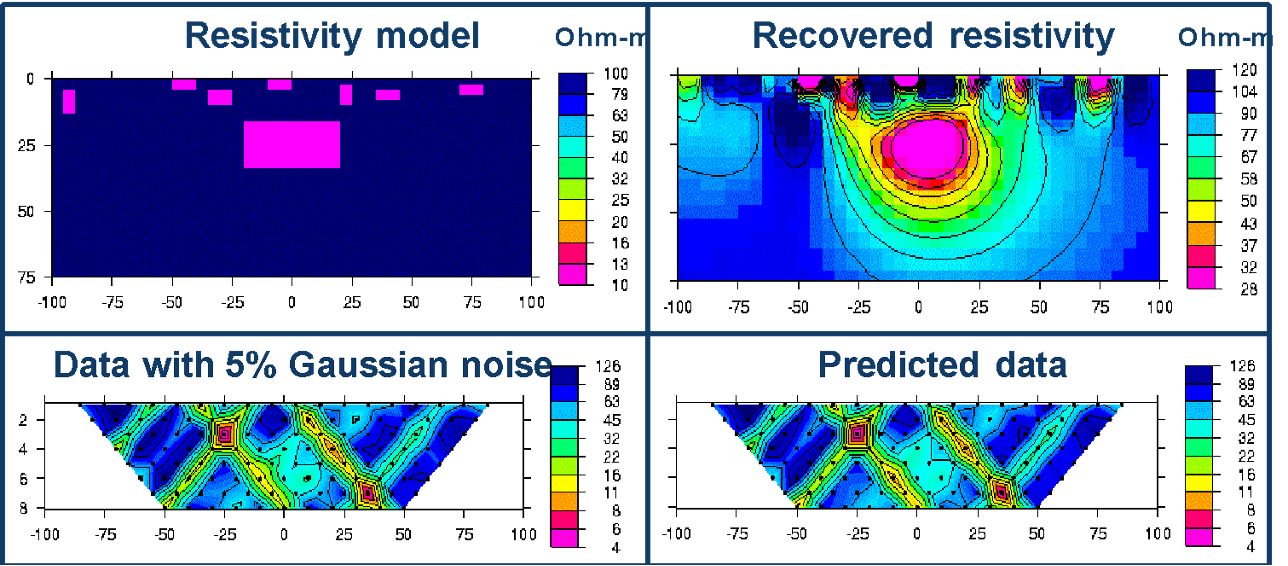
* Dipole-dipole;  n=1,8;  a=10m;  N=316;  ($\alpha_s$, $\alpha_x$, $\alpha_z$)=(.001, 1.0, 1.0)

### Variable Topography
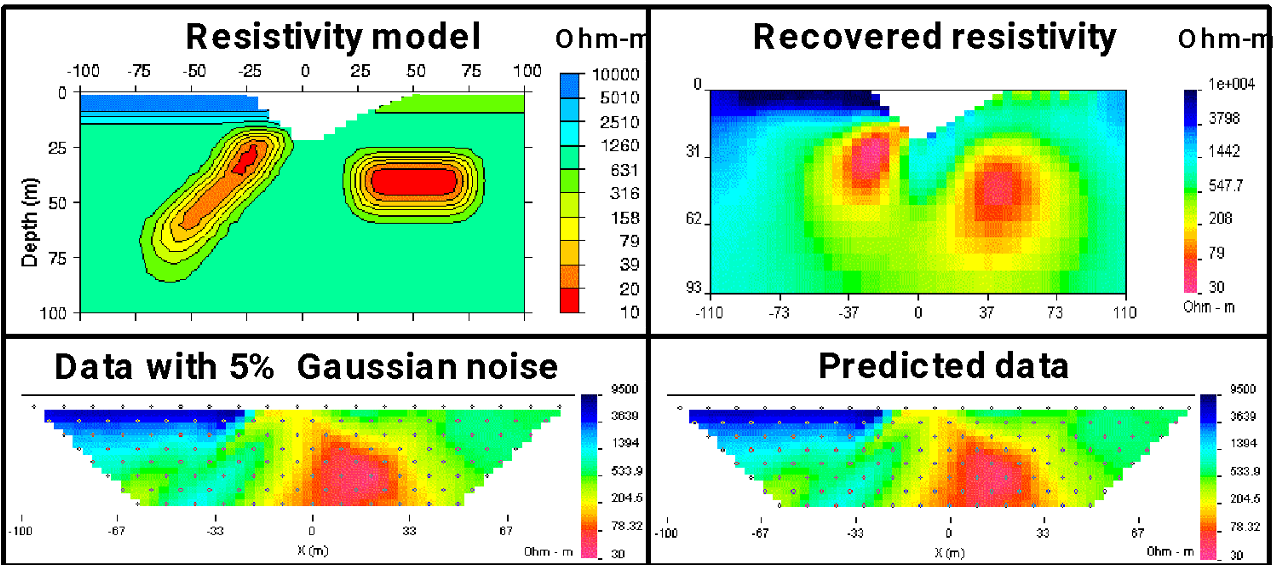
* Pole-dipole;  n=1,8;  a=10m; ($\alpha_s$, $\alpha_x$, $\alpha_z$)=(.001, 1.0, 1.0)

# Sensitivity

To recover a geological structure:
* Data must be sensitive to that structure (i.e., the structure must produce a signature in the data)

Things to consider:
* Are current and potential electrodes coupled with target? (i.e., does the target show up in the data?)
* Is electrode spacing large enough to see deep enough?
* Does enough current penetrate the conductive overburden?

### Example: Two spheres


<div class="row">
<div class="column">

* Electrodes coupled with spheres
* Data sensitive to top of spheres
* Data not sensitive to bottom of spheres
    * why?
</div>
<div class="column">

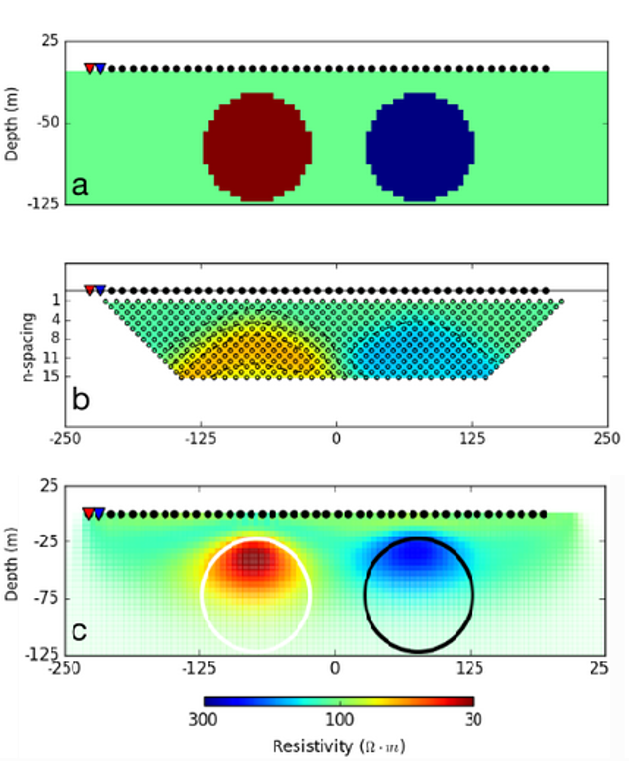
</div>
</div>

---
<div class="row">
<div class="column">
    
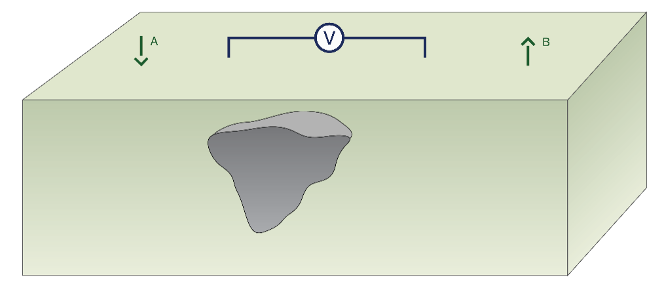
</div>
<div class="column">

Defines how a change in the model would change the data
</div>
</div>

---
<div class="row">
<div class="column">
    
Quantified by the sensitivity!
</div>
<div class="column">

$$ G = \frac{\Delta d}{\delta \sigma} = \frac{\text{change in data}}{\text{change in model}}$$
</div>
</div>

---
Collect the data that are sensitive to the target
* Need to excite the target
* Need to have sensor close to the target

$\rightarrow$ Need “good coupling”

## Exciting the target
* **Total currents:** current from A to B bends *into* the conductive sphere
* **Secondary currents:** the change caused by the sphere, a loop through it
* **Secondary charges:** − where current enters, + where it leaves (resistor → conductor = −)
* **Secondary potential:** a pit on the A side, a hill on the B side

No current at the target → no charges → no signal.
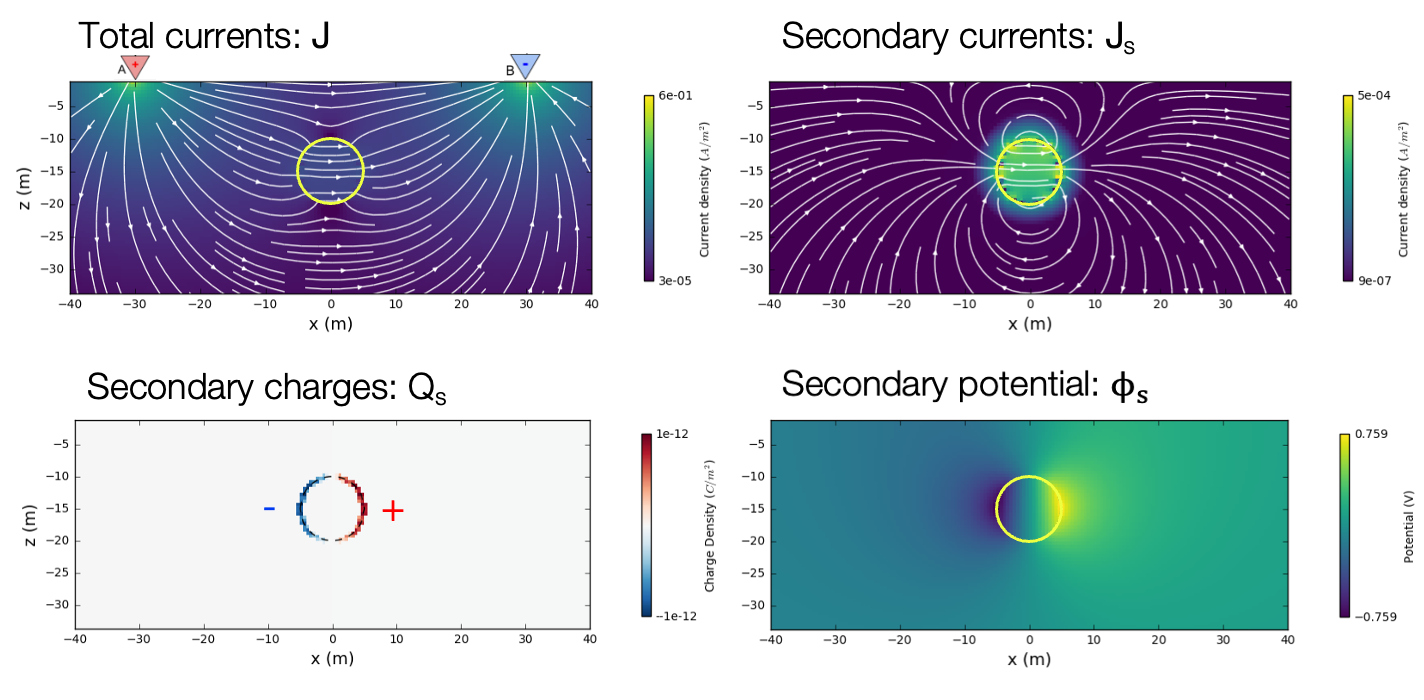

### Measurements:
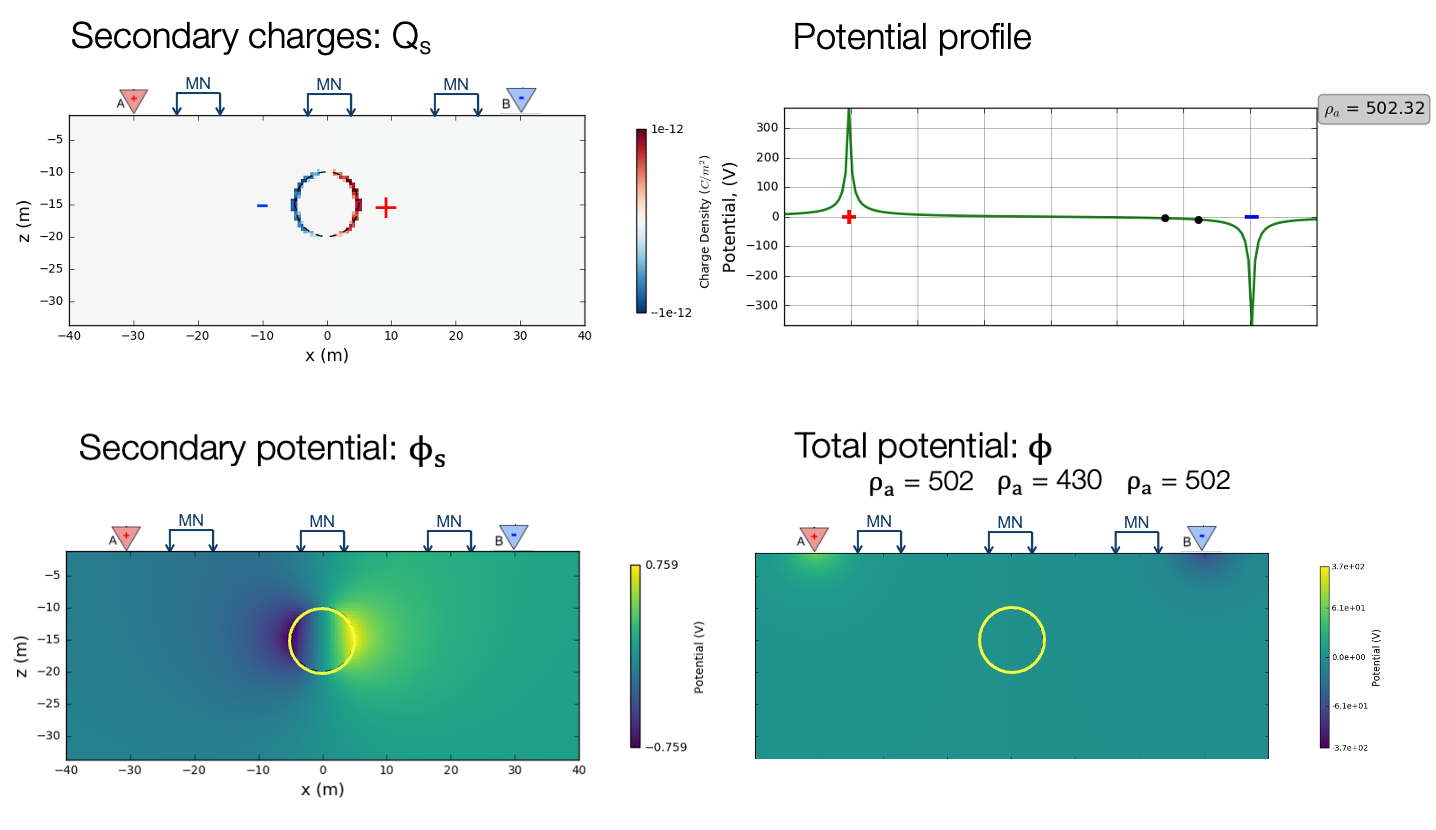
Background is 500 Ωm. Same current source, three potential dipoles:
* Outer MN pairs: ρₐ ≈ 502 Ωm → barely see the sphere
* Middle MN pair: ρₐ = 430 Ωm → sees it

**Q:** Why does only the middle one change? is the sphere a cond. or a resist.?

## Example
### Gradient Array:

<div class="row">
<div class="column">

Q: Do you expect to recover block 1?

Q: Do you expect to recover block 2?
</div>
<div class="column">

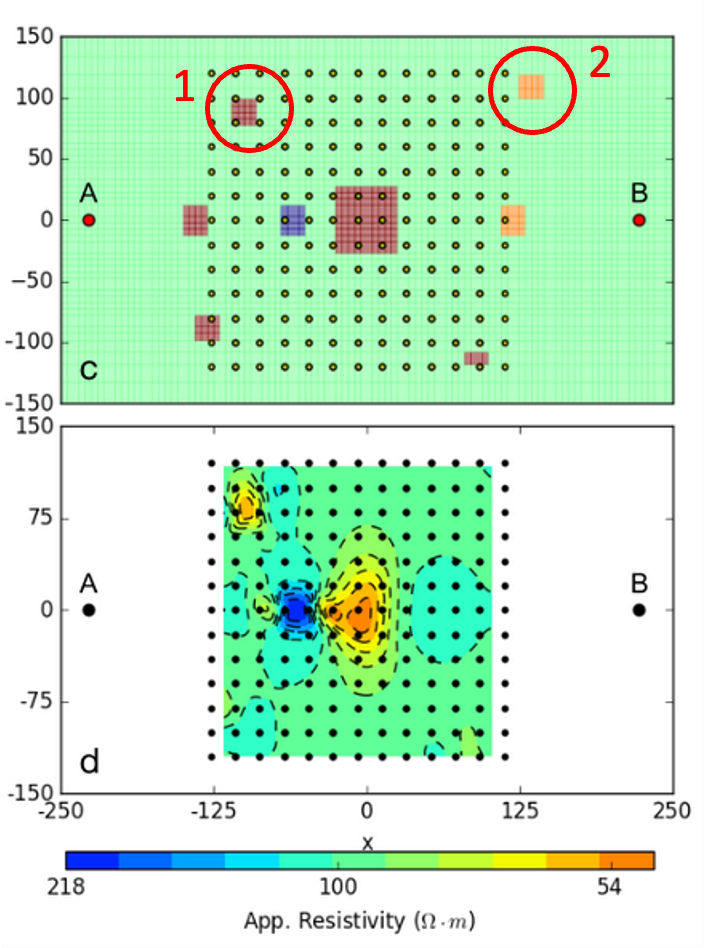
</div>
</div>

### Thin conductive plate:
Different orientation $\rightarrow$ Different coupling $\rightarrow$ Different Data
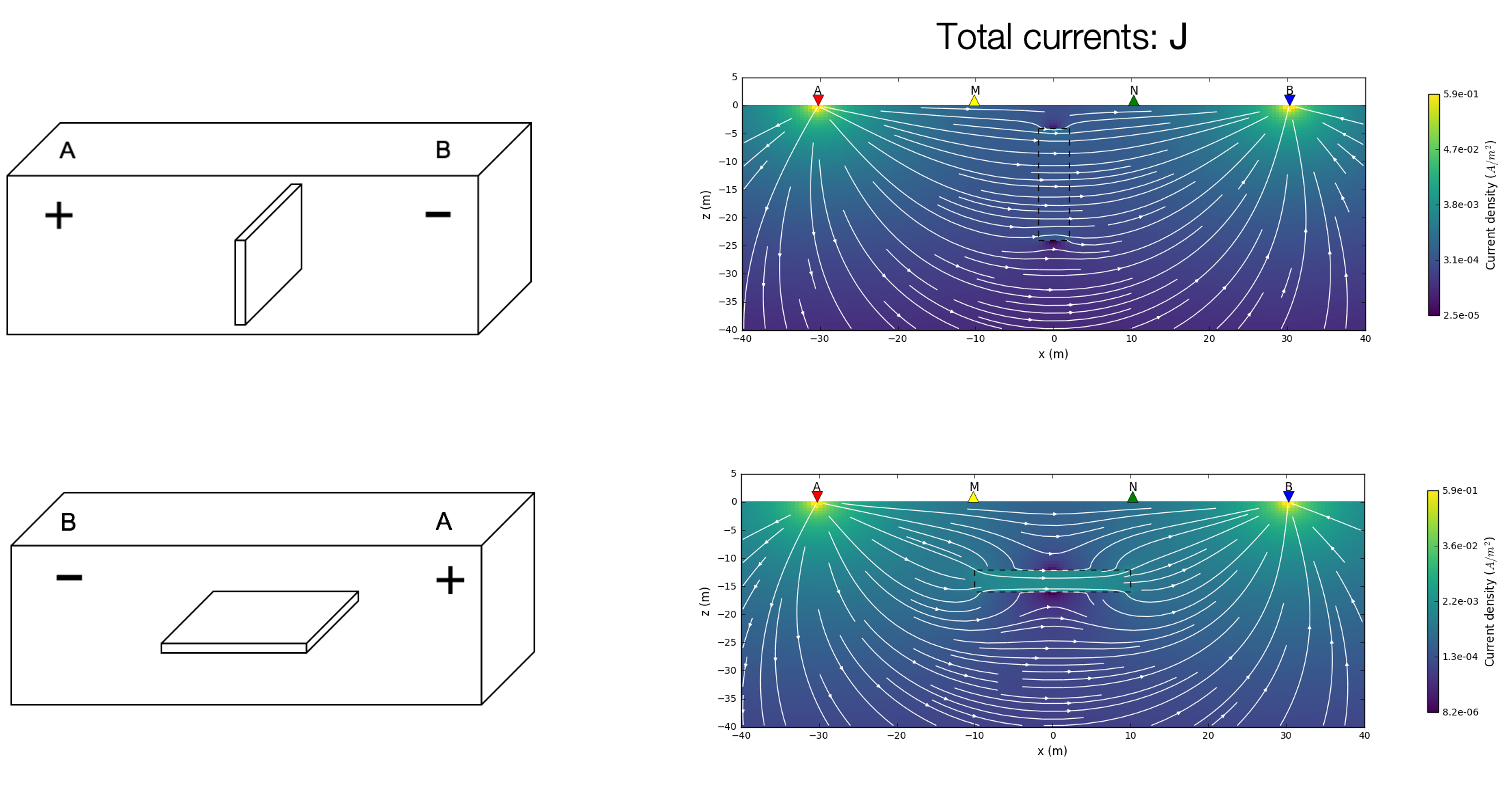

* **Vertical plate (across the current):** current must cross it → strong charges → big signal
* **Horizontal plate (along the current):** current flows past it → weak charges → small signal

Same plate, different orientation, different coupling, different data.

### Conductive vs Resistive plate:
<div class="row">
<div class="column">

**Conductive**

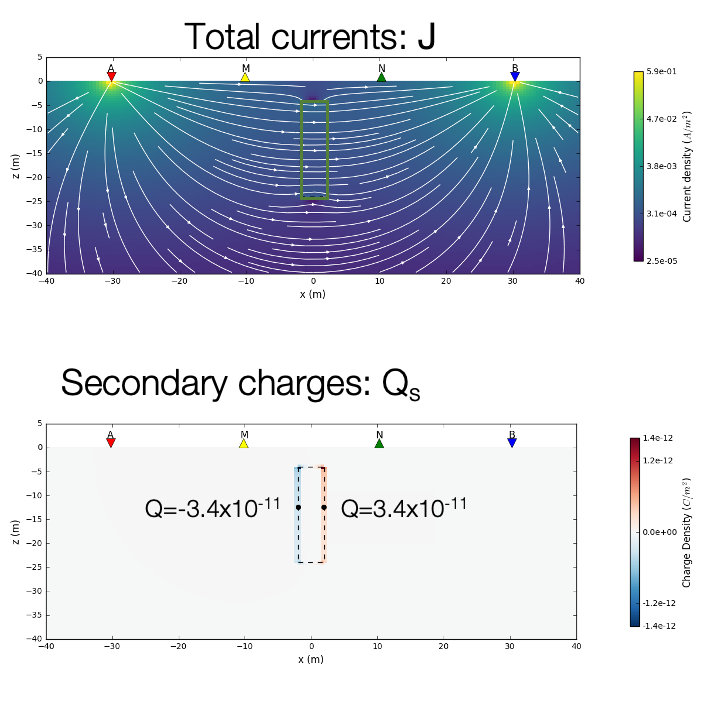
</div>
<div class="column">

**Resistive**

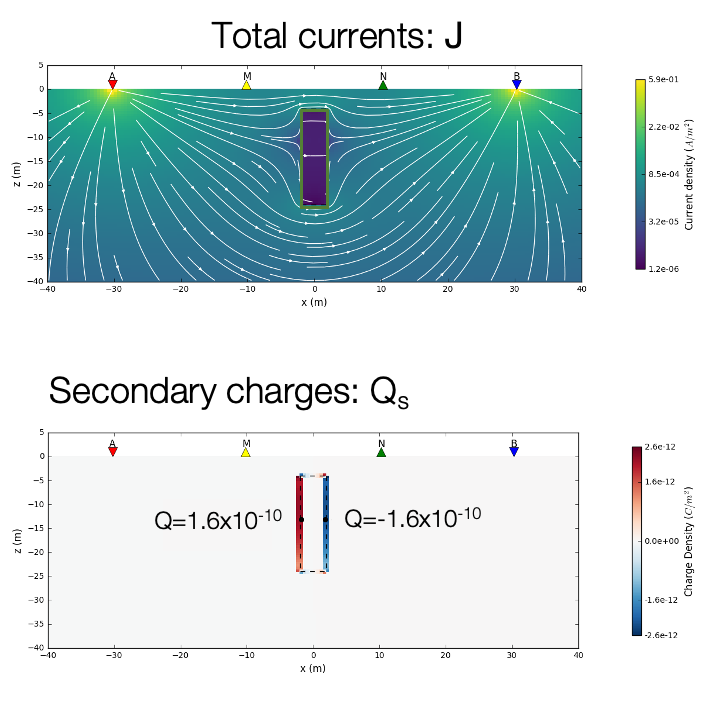
</div>
</div>
Compare the charges on each plate:
* Resistive plate: Q ≈ 1.6 × 10⁻¹⁰
* Conductive plate: Q ≈ 3.4 × 10⁻¹¹ (about 5× smaller)

A thin vertical **resistor** blocks the current → big charge buildup.
A thin vertical **conductor** lets current pass → small charge buildup.

## Sensitivity factors
* “Excite” the target
    * Drive currents to target
    * Need good coupling with target
* Measuring a datum
    * Proximity to target
    * Electrode orientation and separation
* Background resistivity is important
* **For survey design:** put current through the target, put M and N near it, orient lines across it, and watch out for conductive overburden stealing the current.

### Lab 08 Teams

Tomorrow, we'll visit the archaeological to do a small scale gradient survey over the target area. We will all set up the grid. Then Gradient will begin the survey and Schlumberger will set up the Emlid. We will then combine to finish the gradient together. 

Right now, think about roles, timing, priorities, how do we set up the grid (landmarks to know where the walls are so we can set up the grid correctly?), spacing?, lessons from the Schlumberger team, etc.

Your Color teams are for your lab reports.

| Team | Gradient | Name | Schlumberger | Name |
|---|---|---|---|---|
| 🟨 **Yellow** | Team lead | ______ | Safety lead | ______ |
| | Lead wrangler | ______ | Spacing caller | ______ |
| 🟪 **Purple** | Safety lead | ______ | Live plotter | ______ |
| | Station caller | ______ | Flagger | ______ |
| 🟧 **Orange** | Record keeper | ______ | Instrument operator | ______ |
| | M/N mover (2nd) | ______ | A/B crew (A side) | ______ |
| 🟦 **Blue** | Instrument operator | ______ | Record keeper | ______ |
| | M/N mover (1st) | ______ | A/B crew (B side) | ______ |
| 🟩 **Green** | Live plotter | ______ | Team lead | ______ |
| | Wetting/contact | ______ | M/N crew | ______ |

<details>
<summary><b>Click for job descriptions</b></summary>

**Gradient**
* **Team lead:** keeps schedule, decides when to move to next line
* **Safety lead:** calls "Clear!" before each transmit, keeps people off electrodes
* **Record keeper:** records line, M/N stations, V/I, current, error, problems
* **Instrument operator:** runs the Sting R1, contact checks, measurements
* **Live plotter:** tracks V/I along each line, flags jumps or sign flips
* **Station caller:** calls next M/N positions, tracks snaking direction
* **M/N movers:** leapfrog potential electrodes
* **Wetting/contact:** wets electrodes, re-seats bad contacts
* **Lead wrangler:** manages potential leads along the line

**Schlumberger**
* **Team lead:** keeps schedule, decides when to expand
* **Safety lead:** calls "Clear!" before each transmit, watches A and B
* **Record keeper:** records spacings, V/I, current, error, problems
* **Instrument operator:** runs the Sting R1, contact checks, measurements
* **Live plotter:** plots each reading on sketch, flags outliers
* **Spacing caller:** calls next row of spacing table, confirms tape positions
* **A/B crew:** moves, drives, and wets current electrodes (A side / B side)
* **M/N crew:** moves potential electrodes when MN changes
* **Flagger:** flags and labels electrode positions before pulling

</details>

![kafadar](resources/FinalMapGDL-1280x652.png)